# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [9]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\M\Desktop\NLP\LAB-11\Lab_11_QnA_Dataset.csv")

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [11]:
df = pd.read_csv(r"C:\Users\M\Desktop\NLP\LAB-11\Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [13]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [14]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

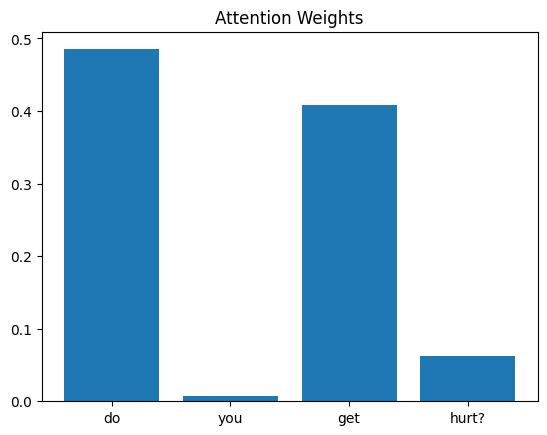

In [15]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Word with highest attention: do

Question: do you have fingers?
Word with highest attention: do

Question: do you ever breathe
Word with highest attention: do



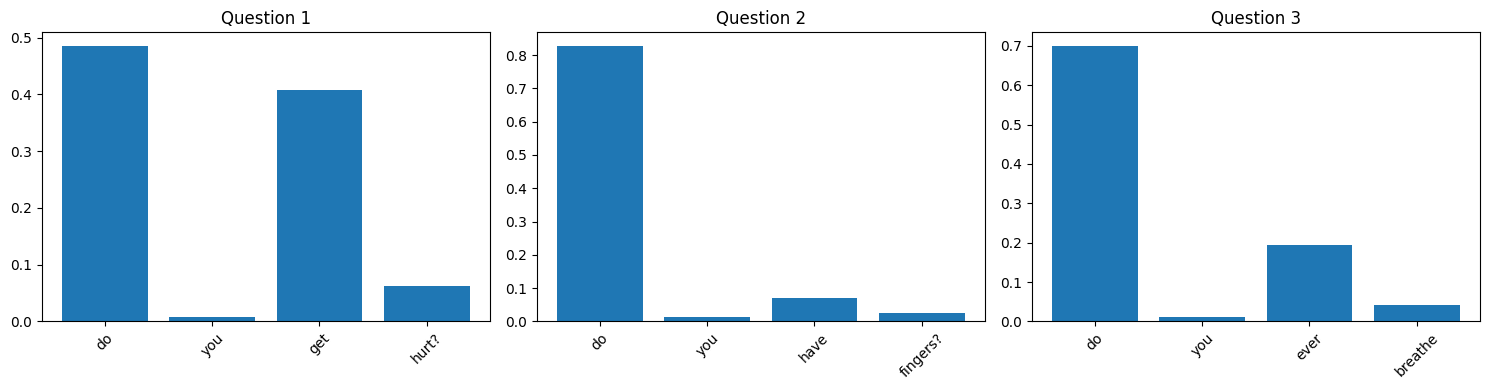

In [18]:
# Select three questions from the dataset.
question_ids = [0, 1, 2]

model.eval()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

with torch.no_grad():
    for i, question_id in enumerate(question_ids):
        question = df["question"].iloc[question_id]
        words = question.split()

        prediction, weights = model(X[question_id:question_id + 1])
        word_weights = weights[0, :len(words)].tolist()

        axes[i].bar(words, word_weights)
        axes[i].set_title(f"Question {i + 1}")
        axes[i].tick_params(axis="x", rotation=45)

        highest_index = word_weights.index(max(word_weights))
        print("Question:", question)
        print("Word with highest attention:", words[highest_index])
        print("")

plt.tight_layout()
plt.show()

Observation:The model gives the highest attention weight to “do” in these questions. Since “do” is a common word, the model may be focusing on a repeated question pattern instead of the main topic of each question.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 1: you're not planning to take over the world right?
Question 2: you're not trying to take over the world right?
Shared content words: {'take', 'over', 'world', 'not', "you're", 'right'}
Word with highest attention: to
Word with highest attention: to


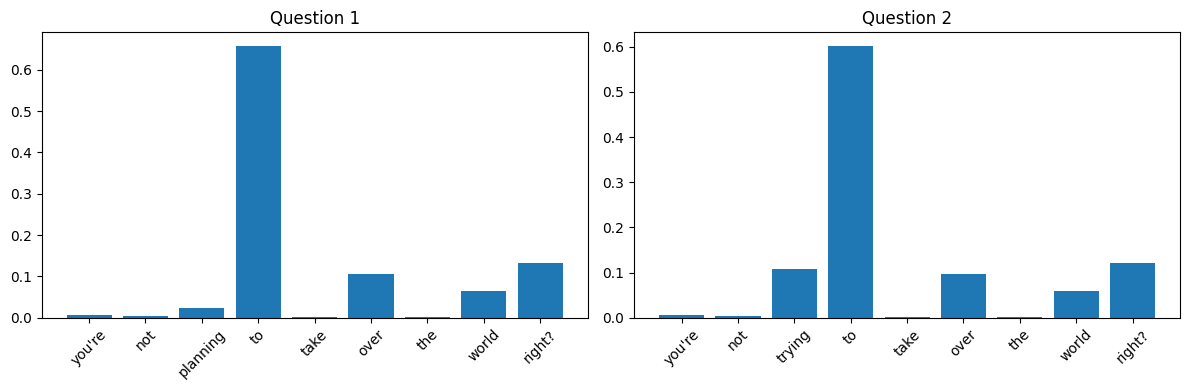

In [19]:
# Find two questions with the same answer and a shared content word.
stop_words = {
    "do", "does", "did", "you", "i", "is", "are", "am",
    "the", "a", "an", "to", "of", "in", "on", "your",
    "my", "it", "what", "how", "when", "where", "why"
}

def get_content_words(question):
    words = question.lower().split()
    words = [word.strip(".,!?;:") for word in words]
    return set(words) - stop_words

candidates = []

for answer_id, group in df.groupby("answer_id", sort=False):
    rows = list(group.iterrows())

    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            index1, row1 = rows[i]
            index2, row2 = rows[j]

            question1 = row1["question"]
            question2 = row2["question"]

            shared_words = (
                get_content_words(question1)
                & get_content_words(question2)
            )

            if question1 != question2 and shared_words:
                candidates.append(
                    (len(shared_words), index1, index2, shared_words)
                )

if len(candidates) == 0:
    print("No suitable question pair was found. Choose two similar questions from the dataset.")
else:
    # Choose the pair with the most shared content words.
    candidates.sort(reverse=True, key=lambda item: item[0])
    _, index1, index2, shared_words = candidates[0]

    question1 = df.loc[index1, "question"]
    question2 = df.loc[index2, "question"]

    print("Question 1:", question1)
    print("Question 2:", question2)
    print("Shared content words:", shared_words)

    question_ids = [
        df.index.get_loc(index1),
        df.index.get_loc(index2)
    ]

    questions = [question1, question2]
    model.eval()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    with torch.no_grad():
        for i, question_id in enumerate(question_ids):
            words = questions[i].split()
            prediction, weights = model(X[question_id:question_id + 1])
            word_weights = weights[0, :len(words)].tolist()

            axes[i].bar(words, word_weights)
            axes[i].set_title(f"Question {i + 1}")
            axes[i].tick_params(axis="x", rotation=45)

            highest_index = word_weights.index(max(word_weights))
            print("Word with highest attention:", words[highest_index])

    plt.tight_layout()
    plt.show()

Observation:The model gives the highest attention weight to “to” in both questions. The attention patterns are similar, but “to” is a common word, so the model may be focusing on the shared sentence structure rather than the main meaning.